# HW2：WHO 平均餘命多元線性回歸

姓名：李易軒　｜　學號：5115056026

依 CRISP-DM 的六階段進行研究；以國家為分組單位，研究在其他國家的年度資料上估計出生時平均餘命。這是同年度關聯與預測練習，不是因果推論或未來預測。

## 1. Business Understanding｜問題理解

根據健康、人口及社經指標，估計國家年度的平均餘命（年）。主要目標為比較多元線性迴歸的 20 特徵與兩種 14 特徵版本；以分國家五折 CV RMSE 選擇 OLS 主模型，再以未見國家的保留集評估。當年度死亡率與目標存在概念及資料建構上的關聯，結果不可解讀為可事前取得資訊的預測，也不代表介入效果。

In [1]:
from pathlib import Path
import hashlib, json, platform, sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import dump, load
from hw2lib.data import validate_data, split_data, TARGET
from hw2lib.modeling import build_models
pd.set_option('display.max_columns', 30)
out = Path('outputs'); out.mkdir(exist_ok=True)
path = Path('dataset/Life Expectancy (WHO)/Life Expectancy Data.csv')
with path.open('rb') as f: sha = hashlib.file_digest(f, 'sha256').hexdigest()
raw = pd.read_csv(path)
print('SHA-256:', sha, '\nRaw shape:', raw.shape)


SHA-256: 872125dd1dd0f9140fbead61df20585a815f5cf47db68f08bf54efaf87963b11 
Raw shape: (2938, 22)


## 2. Data Understanding｜資料理解

來源：[Kaggle Life Expectancy (WHO)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who)，本機原始 CSV 保持不變。國家與年份組成重複觀測；Kaggle 的資料集彙整方式及授權仍須於繳交前核對。

In [2]:
print('Countries:', raw.Country.nunique(), '; years:', raw.Year.min(), '-', raw.Year.max())
print('Duplicate country/year:', raw.duplicated(['Country','Year']).sum())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()}))
display(raw.head())


Countries: 193 ; years: 2000 - 2015
Duplicate country/year: 0


,dtype,missing
Country,str,0
Year,int64,0
Status,str,0
Life expectancy,float64,10
Adult Mortality,float64,10
infant deaths,int64,0
Alcohol,float64,194
percentage expenditure,float64,0
Hepatitis B,float64,553
Measles,int64,0


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 3. Data Preparation｜資料準備

移除缺少目標值的列；只修剪欄位名稱首尾空白，`Developing=0`、`Developed=1`。以國家分組保留約 20% 國家，其餘用於五折 GroupKFold；中位數補值與標準化均在每個訓練折內擬合。國名不進模型，Year 與 Status 分別算一個原始輸入特徵。

Excluded missing target: 10
Predictors: 20 ['Year', 'Status', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']
Train rows/countries: 2336 146 ; holdout rows/countries: 592 37


,count,mean,std,min,25%,50%,75%,max
Year,2336.0,2.007500e+03,4.610759e+00,2000.00000,2003.750000,2.007500e+03,2.011250e+03,2.015000e+03
Status,2336.0,1.643836e-01,3.707026e-01,0.00000,0.000000,0.000000e+00,0.000000e+00,1.000000e+00
Adult Mortality,2336.0,1.620535e+02,1.230928e+02,1.00000,75.000000,1.390000e+02,2.230000e+02,7.230000e+02
infant deaths,2336.0,3.070762e+01,1.294164e+02,0.00000,0.000000,3.000000e+00,2.000000e+01,1.800000e+03
Alcohol,2194.0,4.724508e+00,4.101015e+00,0.01000,0.880000,3.875000e+00,8.010000e+00,1.787000e+01
percentage expenditure,2336.0,7.832849e+02,2.035477e+03,0.00000,8.183629,7.861132e+01,5.002492e+02,1.947991e+04
Hepatitis B,1927.0,8.130825e+01,2.467873e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2336.0,2.190403e+03,1.075877e+04,0.00000,0.000000,1.950000e+01,3.640000e+02,2.121830e+05
BMI,2320.0,3.908366e+01,1.997795e+01,1.00000,21.100000,4.470000e+01,5.650000e+01,7.760000e+01
under-five deaths,2336.0,4.220976e+01,1.756534e+02,0.00000,0.000000,3.000000e+00,2.500000e+01,2.500000e+03


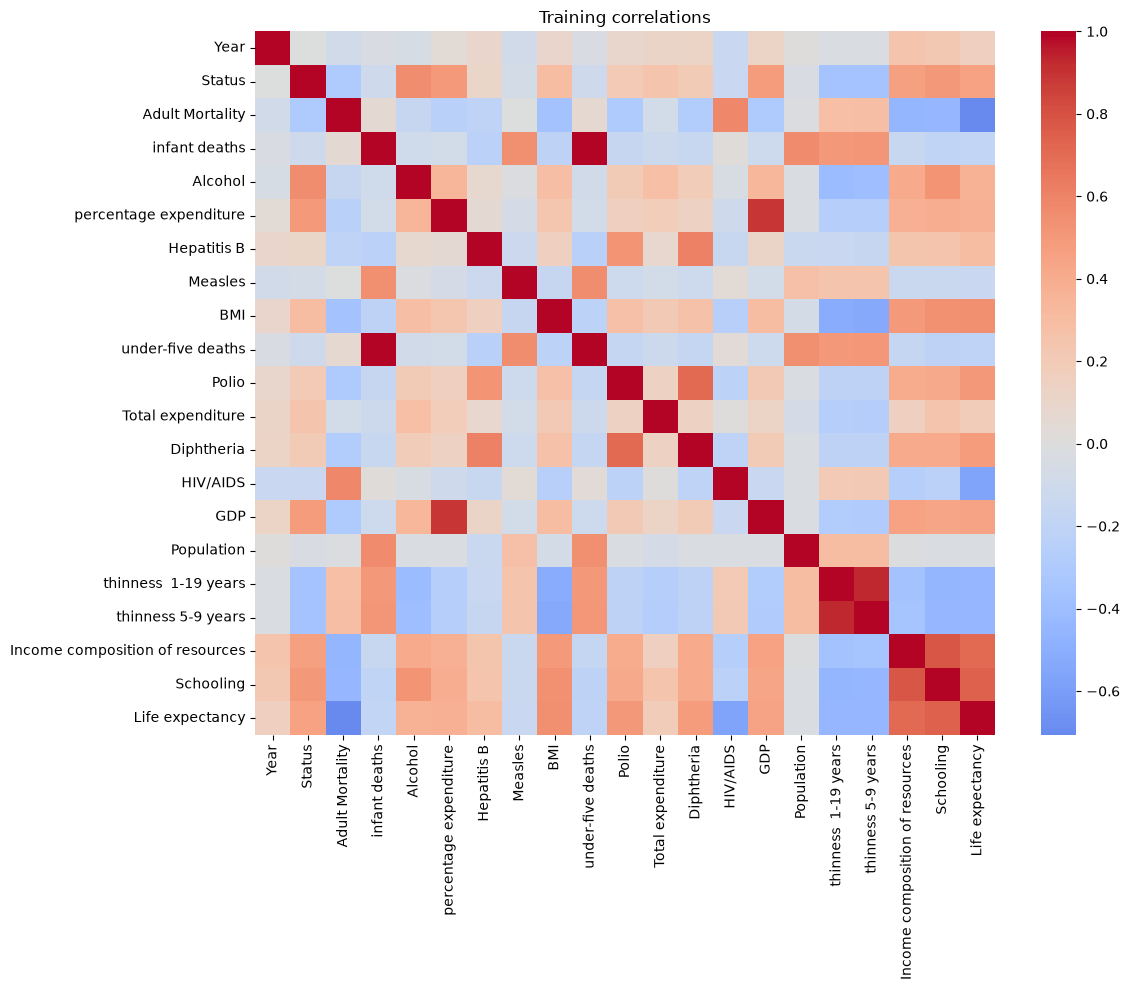

In [3]:
df, features = validate_data(raw)
train, holdout = split_data(df)
X, y, groups = train[features], train[TARGET], train.Country
Xt, yt = holdout[features], holdout[TARGET]
assert set(groups).isdisjoint(holdout.Country)
print('Excluded missing target:', len(raw)-len(df))
print('Predictors:', len(features), features)
print('Train rows/countries:', len(train), groups.nunique(), '; holdout rows/countries:', len(holdout), holdout.Country.nunique())
display(train[features+[TARGET]].describe().T)
plt.figure(figsize=(12,10)); sns.heatmap(train[features+[TARGET]].corr(), cmap='coolwarm', center=0); plt.title('Training correlations'); plt.tight_layout(); plt.savefig(out/'correlation.png', dpi=150); plt.show()


## 4. Modeling｜建模

比較平均值基準、20 特徵 OLS、SelectKBest 與 RFE 各 14 特徵；Ridge/Lasso 為正則化補充。以同一組 GroupKFold 評估所有候選及超參數；訓練 CV 選定後才評估保留集。CV 選參後的最佳 CV 分數可能略樂觀，保留集提供最終評估。

In [4]:
cv = GroupKFold(n_splits=5)
base = build_models(); candidates = {k:clone(base[k]) for k in ['dummy','ols','kbest','rfe']}
for alpha in [0.01,0.1,1,10,100]: candidates[f'ridge_{alpha}'] = clone(base['ridge']).set_params(model__alpha=alpha)
for alpha in [0.00001,0.0001,0.001,0.01,0.1]: candidates[f'lasso_{alpha}'] = clone(base['lasso']).set_params(model__alpha=alpha)
rows=[]
for name, model in candidates.items():
    scores = cross_validate(model, X, y, groups=groups, cv=cv, scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'}, return_train_score=True, n_jobs=1, error_score='raise')
    rows.append({'model':name, 'cv_rmse':-scores['test_rmse'].mean(), 'cv_rmse_sd':scores['test_rmse'].std(), 'cv_mae':-scores['test_mae'].mean(), 'cv_r2':scores['test_r2'].mean(), 'train_cv_rmse':-scores['train_rmse'].mean()})
cv_table=pd.DataFrame(rows).sort_values('cv_rmse'); display(cv_table)
cv_table.to_csv(out/'cv_results.csv', index=False)
selected_ols = cv_table[cv_table.model.isin(['ols','kbest','rfe'])].iloc[0]['model']
chosen = ['dummy', 'ols', 'kbest', 'rfe', cv_table[cv_table.model.str.startswith('ridge_')].iloc[0]['model'], cv_table[cv_table.model.str.startswith('lasso_')].iloc[0]['model']]
print('Selected interpretable OLS:', selected_ols, '; comparisons:', chosen)


,model,cv_rmse,cv_rmse_sd,cv_mae,cv_r2,train_cv_rmse
6,ridge_1,4.270486,0.412119,3.179478,0.785804,4.025111
12,lasso_0.01,4.283753,0.381096,3.183881,0.784119,4.032319
5,ridge_0.1,4.321354,0.477436,3.210893,0.781449,4.019516
11,lasso_0.001,4.323560,0.479580,3.211140,0.781246,4.019536
4,ridge_0.01,4.335501,0.496230,3.216652,0.780152,4.019405
10,lasso_0.0001,4.335815,0.496623,3.216712,0.780123,4.019405
9,lasso_1e-05,4.337117,0.498429,3.217272,0.780003,4.019404
1,ols,4.337264,0.498629,3.217336,0.779989,4.019404
3,rfe,4.337520,0.495752,3.212041,0.779890,4.025548
7,ridge_10,4.395697,0.350150,3.267794,0.772315,4.072290


Selected interpretable OLS: ols ; comparisons: ['dummy', 'ols', 'kbest', 'rfe', 'ridge_1', 'lasso_0.01']


## 5. Evaluation｜評估

選模後一次評估保留國家；以 MAE、MSE、RMSE、R² 比較。Adjusted R² 只對 OLS 計算。由於同國不同年可能相關，傳統 OLS 的獨立誤差、信賴區間與預測區間假設不一定成立；模型選擇的不確定性也未納入區間。

In [5]:
fitted={}; metrics=[]
for name in chosen:
    model=clone(candidates[name]).fit(X,y); fitted[name]=model
    for part, xx, yy in [('train',X,y),('holdout',Xt,yt)]:
        pred=model.predict(xx); mse=mean_squared_error(yy,pred)
        p=14 if name in ('kbest','rfe') else 20
        r2=r2_score(yy,pred)
        adj=1-(1-r2)*(len(yy)-1)/(len(yy)-p-1) if name in ('ols','kbest','rfe') and len(yy)>p+1 else np.nan
        metrics.append({'model':name,'set':part,'MAE':mean_absolute_error(yy,pred),'MSE':mse,'RMSE':np.sqrt(mse),'R2':r2,'adjusted_R2_OLS':adj})
metrics=pd.DataFrame(metrics); display(metrics); metrics.to_csv(out/'metrics.csv',index=False)
model=fitted[selected_ols]; pred=model.predict(Xt); resid=yt.to_numpy()-pred
mask=model.named_steps['select'].get_support() if 'select' in model.named_steps else np.ones(len(features),dtype=bool)
selected=np.array(features)[mask].tolist(); print('Selected features:',selected)
print('Lasso nonzero:', np.count_nonzero(fitted[[x for x in chosen if x.startswith('lasso_')][0]].named_steps['model'].coef_))

selected_by_method = {name: list(np.array(features)[fitted[name].named_steps['select'].get_support()]) for name in ['kbest','rfe']}
print('Feature selection comparison:', json.dumps(selected_by_method, ensure_ascii=False, indent=2))
(out/'selected_features.json').write_text(json.dumps(selected_by_method, ensure_ascii=False, indent=2), encoding='utf-8')

,model,set,MAE,MSE,RMSE,R2,adjusted_R2_OLS
0,dummy,train,7.658068,88.852957,9.426185,0.000000,NaN
1,dummy,holdout,7.982082,98.976038,9.948670,-0.059335,NaN
2,ols,train,2.980324,16.406895,4.050543,0.815348,0.813753
3,ols,holdout,3.121063,16.504293,4.062548,0.823355,0.817168
4,kbest,train,3.081371,17.472598,4.180024,0.803354,0.802168
5,kbest,holdout,3.122318,16.988533,4.121715,0.818173,0.813761
6,rfe,train,2.983844,16.444560,4.055189,0.814924,0.813808
7,rfe,holdout,3.121150,16.511444,4.063428,0.823279,0.818991
8,ridge_1,train,2.981357,16.424923,4.052767,0.815145,NaN
9,ridge_1,holdout,3.115727,16.474742,4.058909,0.823672,NaN


Selected features: ['Year', 'Status', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']
Lasso nonzero: 19
Feature selection comparison: {
  "kbest": [
    "Status",
    "Adult Mortality",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "BMI",
    "Polio",
    "Diphtheria",
    "HIV/AIDS",
    "GDP",
    "thinness  1-19 years",
    "thinness 5-9 years",
    "Income composition of resources",
    "Schooling"
  ],
  "rfe": [
    "Status",
    "Adult Mortality",
    "infant deaths",
    "Alcohol",
    "Hepatitis B",
    "BMI",
    "under-five deaths",
    "Polio",
    "Diphtheria",
    "HIV/AIDS",
    "GDP",
    "thinness  1-19 years",
    "Income composition of resources",
    "Schooling"
  ]
}


584

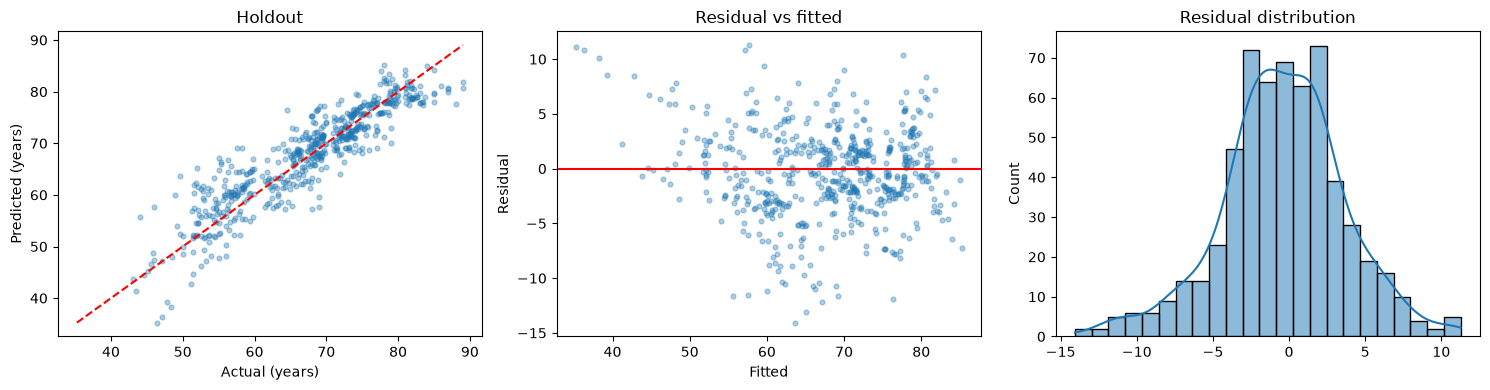

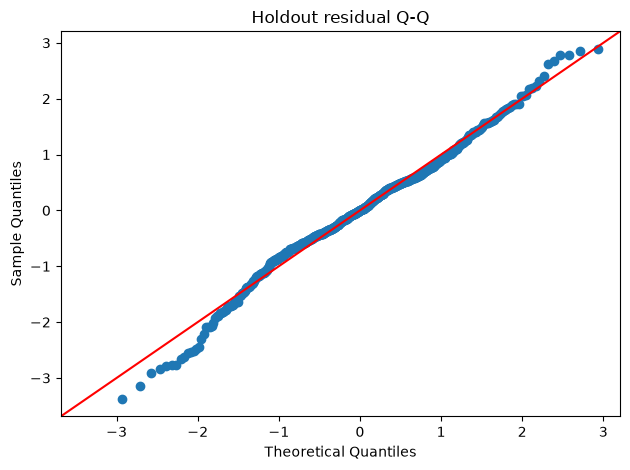

In [6]:
fig, ax=plt.subplots(1,3,figsize=(15,4))
ax[0].scatter(yt,pred,alpha=.35,s=12); lo=min(yt.min(),pred.min()); hi=max(yt.max(),pred.max()); ax[0].plot([lo,hi],[lo,hi],'r--'); ax[0].set(xlabel='Actual (years)',ylabel='Predicted (years)',title='Holdout')
ax[1].scatter(pred,resid,alpha=.35,s=12); ax[1].axhline(0,color='r'); ax[1].set(xlabel='Fitted',ylabel='Residual',title='Residual vs fitted')
sns.histplot(resid,kde=True,ax=ax[2]); ax[2].set(title='Residual distribution')
plt.tight_layout(); plt.savefig(out/'holdout_diagnostics.png',dpi=150); plt.show()
sm.qqplot(resid,line='45',fit=True); plt.title('Holdout residual Q-Q'); plt.tight_layout(); plt.savefig(out/'qq.png',dpi=150); plt.show()


Breusch–Pagan (train; LM, LM p, F, F p): (np.float64(330.8497507671472), np.float64(3.87856582274311e-58), np.float64(19.09874767037973), np.float64(4.342735989109681e-63))
Durbin–Watson is omitted: arbitrary row ordering cannot establish independence.


,feature,VIF
3,infant deaths,189.062756
9,under-five deaths,187.720430
17,thinness 5-9 years,7.905426
16,thinness 1-19 years,7.651903
14,GDP,5.620855
5,percentage expenditure,5.462361
19,Schooling,3.398117
18,Income composition of resources,2.955566
12,Diphtheria,2.289077
10,Polio,2.166098


,feature,standardized_coefficient
9,under-five deaths,-13.370732
2,Adult Mortality,-2.669552
13,HIV/AIDS,-2.037092
6,Hepatitis B,-0.364371
16,thinness 1-19 years,-0.355567
7,Measles,-0.147690
0,Year,-0.136322
15,Population,-0.104373
17,thinness 5-9 years,0.014640
5,percentage expenditure,0.039506


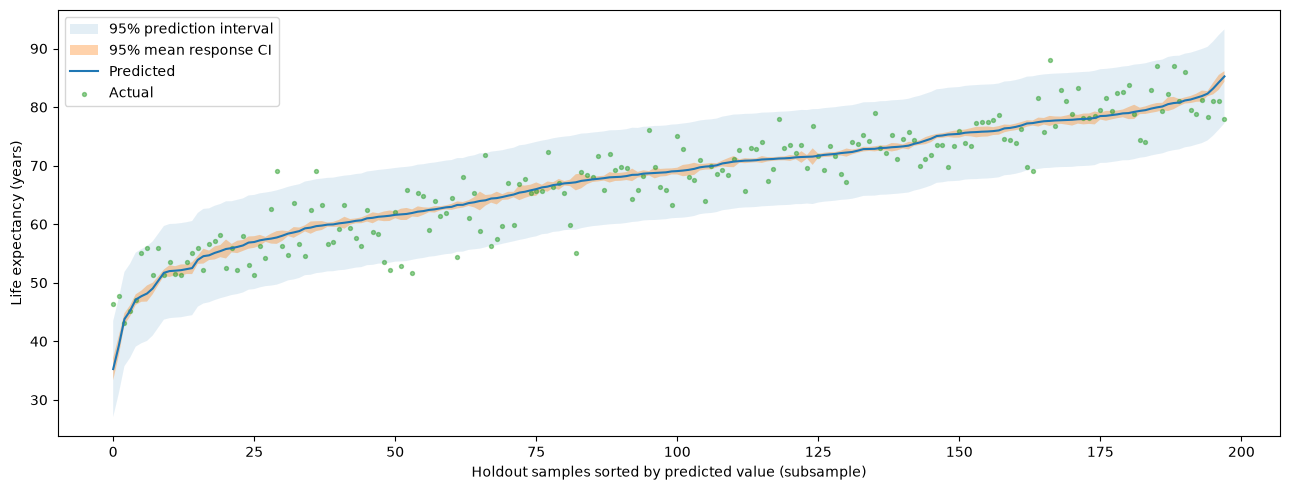

In [7]:
# Match sklearn preprocessing and selected feature ordering exactly.
trans_train=model.named_steps['scale'].transform(model.named_steps['impute'].transform(X))[:,mask]
trans_test=model.named_steps['scale'].transform(model.named_steps['impute'].transform(Xt))[:,mask]
A=sm.add_constant(trans_train, has_constant='add'); B=sm.add_constant(trans_test, has_constant='add')
ols=sm.OLS(y.to_numpy(),A).fit(); intervals=ols.get_prediction(B).summary_frame(alpha=.05)
assert np.allclose(ols.predict(B),pred,rtol=1e-7,atol=1e-7)
assert np.all((intervals.obs_ci_upper-intervals.obs_ci_lower) >= (intervals.mean_ci_upper-intervals.mean_ci_lower)-1e-10)
print('Breusch–Pagan (train; LM, LM p, F, F p):',het_breuschpagan(ols.resid,A))
print('Durbin–Watson is omitted: arbitrary row ordering cannot establish independence.')
vif=pd.DataFrame({'feature':selected,'VIF':[variance_inflation_factor(A,i+1) for i in range(len(selected))]}); display(vif.sort_values('VIF',ascending=False))
coef=pd.DataFrame({'feature':selected,'standardized_coefficient':model.named_steps['model'].coef_}).sort_values('standardized_coefficient'); display(coef)
coef.to_csv(out/'coefficients.csv',index=False); vif.to_csv(out/'vif.csv',index=False)
order=np.argsort(pred); ix=order[::max(1,len(order)//150)]; z=intervals.iloc[ix].reset_index(drop=True); xx=np.arange(len(ix))
plt.figure(figsize=(13,5)); plt.fill_between(xx,z.obs_ci_lower,z.obs_ci_upper,alpha=.12,label='95% prediction interval'); plt.fill_between(xx,z.mean_ci_lower,z.mean_ci_upper,alpha=.35,label='95% mean response CI'); plt.plot(xx,pred[ix],label='Predicted'); plt.scatter(xx,yt.to_numpy()[ix],s=8,alpha=.5,label='Actual'); plt.xlabel('Holdout samples sorted by predicted value (subsample)'); plt.ylabel('Life expectancy (years)'); plt.legend(); plt.tight_layout(); plt.savefig(out/'intervals.png',dpi=150); plt.show()


### 診斷與限制

- 線性及同質變異：觀察殘差與擬合值，並參考 Breusch–Pagan；p 值與圖形都需解讀。
- 常態性：觀察 Q-Q 圖及殘差分布；預測本身不要求目標常態。
- 獨立性：同國跨年度觀測可能相關，分國家切分降低跨集合洩漏，但不保證訓練誤差獨立；傳統區間可能失準。
- 共線性：查看 VIF 與相關圖；無限值表示設計矩陣奇異。
- 死亡率等變數與平均餘命在概念或資料製作上可能重疊，係數不能當作因果效果。缺失並非必然隨機，中位數補值可能造成偏差；來源、更新與授權需核對。

本次執行中，20 特徵 OLS 的分國家 CV RMSE 為 4.337 年；保留集 RMSE 為 4.063 年、R² 為 0.823。RFE 的 CV RMSE 為 4.338 年，與 OLS 幾乎相同；KBest 為 4.635 年。訓練資料 Breusch–Pagan p 值約 3.88e-58，提供異質變異的證據，但同國觀測相依使傳統檢定解讀受限。infant deaths 與 under-five deaths 的 VIF 約 189 與 188，顯示嚴重共線性；兩者係數不宜單獨作政策解讀。

## 6. Deployment｜部署

儲存完整前處理及 OLS；示範模型重載一致性。新資料需具備相同的 20 欄，並以相同規則將 Status 轉成 0/1；這是本機研究示範。

In [8]:
dump({'pipeline':model,'features':features,'selected':selected,'target':TARGET,'status_mapping':{'Developing':0,'Developed':1}},out/'life_expectancy_model.joblib')
restored=load(out/'life_expectancy_model.joblib'); assert np.allclose(restored['pipeline'].predict(Xt),pred)
pd.DataFrame({'Country':holdout.Country.to_numpy(),'Year':holdout.Year.to_numpy(),'actual':yt.to_numpy(),'prediction':pred}).to_csv(out/'holdout_predictions.csv',index=False)
meta={'source':'https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who','sha256':sha,'python':sys.version,'platform':platform.platform(),'seed':42,'selected_ols':selected_ols,'features':features,'selected_features':selected,'split':'GroupShuffleSplit country, 20% groups; GroupKFold 5','raw_rows':len(raw),'usable_rows':len(df)}
(out/'metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
print('Model saved and reload verified. Outputs:', out.resolve())


Model saved and reload verified. Outputs: C:\Users\User\中興課程\01_物聯網\week7\hw_2\outputs


## AI 使用與待補證據

本 Notebook 使用 Codex 協助程式與文字整理，須附上真實對話匯出。NotebookLM 摘要須由實際使用 NotebookLM 的研究紀錄撰寫（至少 100 字），不可虛構。繳交前核對資料授權、課程最新規範與學號命名，以及報告中的結果與本次執行輸出一致。